# Green logistics scenario appraisal

Decision: select lane consolidation choices within spend and service limits. All observations and factors are synthetic. Outputs are conditional projections, not observed cost or emissions savings. Built with AI assistance.

In [1]:
import json
from pathlib import Path

import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "artifacts/demo"
print("Retail and churn mode: seeded synthetic offline demo. Logistics: synthetic.")

Retail and churn mode: seeded synthetic offline demo. Logistics: synthetic.


In [2]:
from portfolio.logistics import generate_deliveries, optimise_lanes, summarise_lanes

assumptions = json.loads((ROOT / "config/logistics.json").read_text())
shipments = generate_deliveries()
lanes = summarise_lanes(shipments, assumptions["illustrative_diesel_kg_co2e_per_km"])
lanes

,lane,shipments,distance_km,cost_gbp,co2e_kg,on_time_rate
0,Edinburgh–Aberdeen,767,162210.45,112442.60,40552.6125,0.834420
1,Edinburgh–Dundee,778,84532.92,69661.64,21133.2300,0.898458
2,Edinburgh–Glasgow,739,72692.53,62330.93,18173.1325,0.910690
3,Edinburgh–Inverness,704,181706.79,121034.36,45426.6975,0.775568
4,Edinburgh–Perth,742,61586.43,56050.12,15396.6075,0.924528
5,Edinburgh–Stirling,761,51037.88,50917.94,12759.4700,0.901445
6,Glasgow–Aberdeen,766,186457.42,125411.48,46614.3550,0.804178
7,Glasgow–Inverness,743,207583.68,136682.19,51895.9200,0.802153


## 1. Enumerate every defined choice

Eight binary choices create 256 combinations. The objective is minimum illustrative emissions, constrained by a maximum 4% spend increase and 84% shipment-weighted service.

In [3]:
plan, summary, candidates = optimise_lanes(lanes, assumptions)
print(
    {
        k: summary[k]
        for k in [
            "scenarios_evaluated",
            "feasible_scenarios",
            "co2e_reduction_pct",
            "cost_increase_gbp",
            "scenario_on_time_rate",
        ]
    }
)
plan[["lane", "consolidate", "scenario_cost_gbp", "scenario_co2e_kg", "scenario_on_time_rate"]]

{'scenarios_evaluated': 256, 'feasible_scenarios': 128, 'co2e_reduction_pct': 0.11577841575196712, 'cost_increase_gbp': 28711.07520000008, 'scenario_on_time_rate': 0.8514075}


,lane,consolidate,scenario_cost_gbp,scenario_co2e_kg,scenario_on_time_rate
0,Edinburgh–Aberdeen,True,121438.0080,31631.03775,0.819420
1,Edinburgh–Dundee,False,69661.6400,21133.23000,0.898458
2,Edinburgh–Glasgow,False,62330.9300,18173.13250,0.910690
3,Edinburgh–Inverness,True,130717.1088,35432.82405,0.760568
4,Edinburgh–Perth,False,56050.1200,15396.60750,0.924528
5,Edinburgh–Stirling,False,50917.9400,12759.47000,0.901445
6,Glasgow–Aberdeen,True,135444.3984,36359.19690,0.789178
7,Glasgow–Inverness,False,136682.1900,51895.92000,0.802153


In [4]:
assert len(candidates) == 256
assert summary["scenario_co2e_kg"] == candidates[candidates.feasible].co2e_kg.min()
assert summary["scenario_cost_gbp"] <= summary["baseline_cost_gbp"] * 1.04 + 1e-6
assert summary["scenario_on_time_rate"] >= 0.84

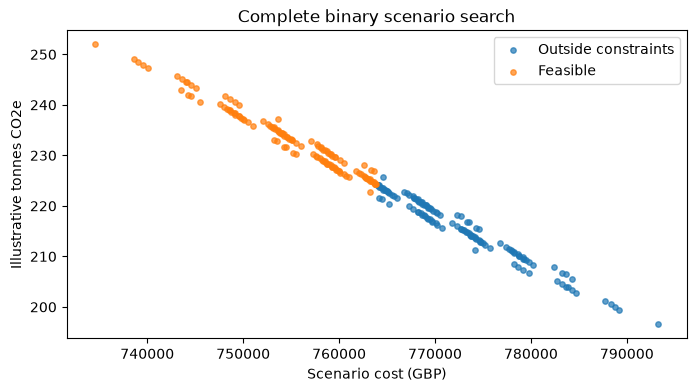

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for feasible, group in candidates.groupby("feasible"):
    ax.scatter(
        group.cost_gbp,
        group.co2e_kg / 1000,
        label="Feasible" if feasible else "Outside constraints",
        s=15,
        alpha=0.7,
    )
ax.set(
    xlabel="Scenario cost (GBP)",
    ylabel="Illustrative tonnes CO2e",
    title="Complete binary scenario search",
)
ax.legend()
plt.show()

## 2. Sensitivity and infeasibility

Ask what a stricter service constraint does to the decision rather than showing only a favourable scenario.

In [6]:
sensitivity = []
for target in [0.80, 0.84, 0.85, 0.86, 0.90]:
    scenario = {**assumptions, "minimum_weighted_on_time_rate": target}
    try:
        _, result, _ = optimise_lanes(lanes, scenario)
        sensitivity.append(
            {
                "service_target": target,
                "feasible": True,
                "emissions_reduction": result["co2e_reduction_pct"],
            }
        )
    except ValueError:
        sensitivity.append(
            {"service_target": target, "feasible": False, "emissions_reduction": None}
        )
pd.DataFrame(sensitivity)

,service_target,feasible,emissions_reduction
0,0.80,True,0.115778
1,0.84,True,0.115778
2,0.85,True,0.115778
3,0.86,False,NaN
4,0.90,False,NaN


## 3. Business analysis handoff

The project README maps user stories to acceptance checks and proposes accountable roles. Validate actual carrier capacity, kilometres, load allocation, emissions factors and costs. Pilot one lane, agree rollback criteria and measure service and absolute emissions. This is not a route optimiser or carbon audit.